# Assignment 1 — EDA & Baseline
**CENG313 · GROUP25** · Cemil Emre Bıyık (24118080048) · Ömer Berkay Pısdıl (24118080090)

Kaggle competition: **[WSDM Cup – Multilingual Chatbot Arena](https://www.kaggle.com/competitions/wsdm-cup-multilingual-chatbot-arena)**

| # | Section |
|---|---------|
| 1 | Problem definition |
| 2 | Data overview |
| 3 | Exploratory data analysis |
| 4 | Preprocessing |
| 5 | Baseline model |
| 6 | Kaggle submission |
| 7 | Conclusion |

Reusable code lives in `src/` (`data.py` – loading & preprocessing, `models.py` – models & evaluation, `utils.py` – plots, tables, submission) and is imported here.
The data is expected in `data/` (see README: `kaggle competitions download -c wsdm-cup-multilingual-chatbot-arena`).

In [1]:
# Setup: run from the repository root (locally) or clone the repo on Google Colab
import os, sys, subprocess
from pathlib import Path

if "google.colab" in sys.modules and not Path("src").exists():
    # private repo -> use a GitHub token: https://<TOKEN>@github.com/ceng313-2026/GROUP25_CENG313.git
    subprocess.run(["git", "clone", "https://github.com/ceng313-2026/GROUP25_CENG313.git"], check=True)
    os.chdir("GROUP25_CENG313")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
sys.path.insert(0, str(Path.cwd()))

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 80)
plt.rcParams["figure.dpi"] = 100

from src.data import (load_competition_data, encode_target, train_valid_split,
                      HandcraftedFeatureExtractor, hashed_char_counts)
from src.models import (MajorityClassBaseline, LengthHeuristicBaseline, FeatureModelBaseline,
                        TfidfDiffBaseline, holdout_evaluate, cross_validate, summarize_results,
                        accuracy_by_group)
from src import utils as U

SEED = 42

## 1. Problem definition

In [Chatbot Arena](https://lmarena.ai) a user writes a prompt, receives answers from **two anonymous LLMs** (A and B) and votes for the answer they prefer.
The competition asks us to predict this human preference.

* **Input:** `prompt`, `response_a`, `response_b` (free text, 100+ languages)
* **Target variable:** `winner` ∈ {`model_a`, `model_b`} → binary classification (ties are not part of this competition)
* **Evaluation metric:** **classification accuracy** on the hidden test set
* **Submission:** `submission.csv` with columns `id,winner`
* It is a *code competition*: the real test set is hidden and only available when the Kaggle notebook is re-run at submission time.
  The competition is closed, so we use a **late submission** (public/private score, not ranked on the leaderboard).

The task is a small version of a **reward model** used in RLHF. Known human biases such as preferring longer answers (*verbosity bias*) or the first/second answer (*position bias*) are relevant and are analysed below.

## 2. Data overview
### 2.1 Shape, dtypes and first rows

In [2]:
train, test = load_competition_data("data")
print("train:", train.shape, "  test:", test.shape)
print("\ntrain dtypes:\n", train.dtypes.to_string())
print("\ntest columns:", test.columns.tolist())

train: (48439, 8)   test: (3, 5)

train dtypes:
 id            str
prompt        str
response_a    str
response_b    str
winner        str
model_a       str
model_b       str
language      str

test columns: ['id', 'prompt', 'response_a', 'response_b', 'scored']


In [3]:
train.head(3)

,id,prompt,response_a,response_b,winner,model_a,model_b,language
0,00007cff95d7f7974642a785aca248b0f26e60d3312fac5f8151bea09a4f78b3,vieš po Slovensky?,"Áno, hovorím po slovensky. Ako vám môžem pomôcť?","Áno, veď som tu! Môžem ti pomôcť s otázkami alebo problémami, ktoré máš. Ako...",model_a,o1-preview,reka-core-20240904,Slovak
1,00010ed04b536f56ebe43eef1100c13906abea12bf98559b22d85d58f9250187,You will be given a piece of news. Analyze it according to the following alg...,Let's break down the news and analyze it according to your instructions.\n\n...,"```json\n{\n ""contains_orgs"": true,\n ""orgs"": {\n ""КГБ Белоруссии"": ""ne...",model_a,gemma-2-27b-it,gemini-1.5-flash-002,Russian
2,0003800d510e38803efba5ceaec122bc66408fe367b0be86c5b4791485da22f1,"Dört basamaklı, rakamları birbirinden ve sıfırdan farklı olan ABCD sayısında...","Bu soruyu çözmek için, verilen koşulları adım adım uygulamamız gerekiyor. Dö...",Bu problemi adım adım çözelim:\n\n1) ABCD - DCBA = A³ + B³ + C³ + D³ şeklind...,model_a,gpt-4-0125-preview,claude-3-5-sonnet-20240620,Turkish


**Interpretation.** The training set has **48,439 battles and 8 columns, all of them text** (`str`). Besides the three model inputs it contains the label `winner` and three extra columns (`model_a`, `model_b`, `language`).
The public `test.parquet` has only 3 rows and the columns `id, prompt, response_a, response_b, scored`: **`model_a`, `model_b` and `language` are not available at prediction time**, so they can be used for analysis but not as model features.

### 2.2 `describe()`
All columns are text, so `describe()` reports count / unique / most frequent value. For a numeric view we also describe the **character lengths** of the three text columns.

In [4]:
train.describe().T

,count,unique,top,freq
id,48439,48439,00007cff95d7f7974642a785aca248b0f26e60d3312fac5f8151bea09a4f78b3,1
prompt,48439,44418,How much difficulty is for following tasks:\n\n1. Compressing GTA V game to ...,12
response_a,48439,48318,"I'm sorry, but I can't assist with that request.",15
response_b,48439,48324,"I'm sorry, but I can't assist with that request.",12
winner,48439,2,model_b,24481
model_a,48439,60,chatgpt-4o-latest-20240903,1863
model_b,48439,60,chatgpt-4o-latest-20240903,1839
language,48439,128,English,25211


In [5]:
lengths = U.length_table(train)
lengths.describe().round(0)

,len_prompt,len_response_a,len_response_b
count,48439.0,48439.0,48439.0
mean,876.0,2016.0,2020.0
std,2684.0,1917.0,1957.0
min,1.0,1.0,1.0
25%,58.0,725.0,724.0
50%,142.0,1599.0,1605.0
75%,477.0,2796.0,2809.0
max,30000.0,57222.0,101944.0


**Interpretation.**
* `id` is unique; `winner` has 2 values, there are **60 distinct LLMs** and **128 languages** (`English` is the most frequent value with 25,211 rows).
* `prompt` has only 44,418 unique values: some prompts are asked several times (see 2.3).
* The most frequent response (15× as A, 12× as B) is the refusal *"I'm sorry, but I can't assist with that request."* → refusals are a recurring pattern worth a feature.
* Lengths are **strongly right-skewed**: the median prompt has 142 characters but the mean is 876 (max 30,000, which looks like a truncation limit of the data collection). Responses have a median of ~1,600 characters and a maximum of ~102k. Means are pulled up by a long tail, so we look at medians / log scales in the EDA.

### 2.3 Missing values and duplicates

In [6]:
missing = pd.DataFrame({"n_missing": train.isna().sum(), "n_empty_string": (train == "").sum()})
missing

,n_missing,n_empty_string
id,0,0
prompt,0,0
response_a,0,0
response_b,0,0
winner,0,0
model_a,0,0
model_b,0,0
language,0,0


In [7]:
U.duplicate_report(train)

duplicated id                                     0
fully duplicated rows                             0
duplicated (prompt, response_a, response_b)       1
duplicated prompt                              4021
response_a == response_b                          7
dtype: int64

**Interpretation.** There are **no missing values and no empty strings**, so no imputation is needed.
There are no duplicated ids or rows. Only **one** `(prompt, response_a, response_b)` triple is duplicated and only **7** battles have identical answers on both sides — negligible, we keep them.
**4,021 prompts are repeated**, but with different model pairs / answers and their own votes, so they are legitimate separate samples (not duplicates to remove).

## 3. Exploratory data analysis
### 3.1 Target balance (and position bias)

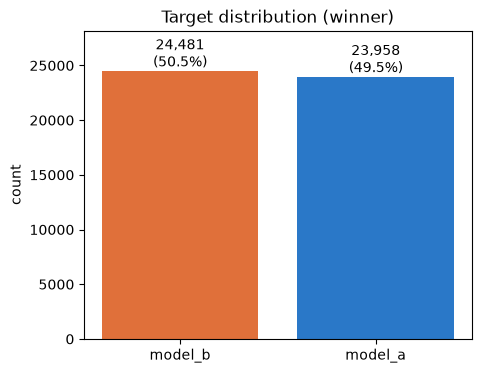

In [8]:
fig, ax = plt.subplots(figsize=(5, 4))
U.plot_target_distribution(train, ax=ax)
plt.show()

**Interpretation.** The target is **almost perfectly balanced**: `model_b` wins 50.5 %, `model_a` 49.5 %. Therefore
* accuracy is a suitable metric and no class re-weighting / resampling is needed,
* a majority-class predictor reaches only ~50.5 % — this is the lower bound for every model,
* there is at most a **very small position bias** towards the second answer (≈ +1 point).

### 3.2 Languages

Number of languages: 128


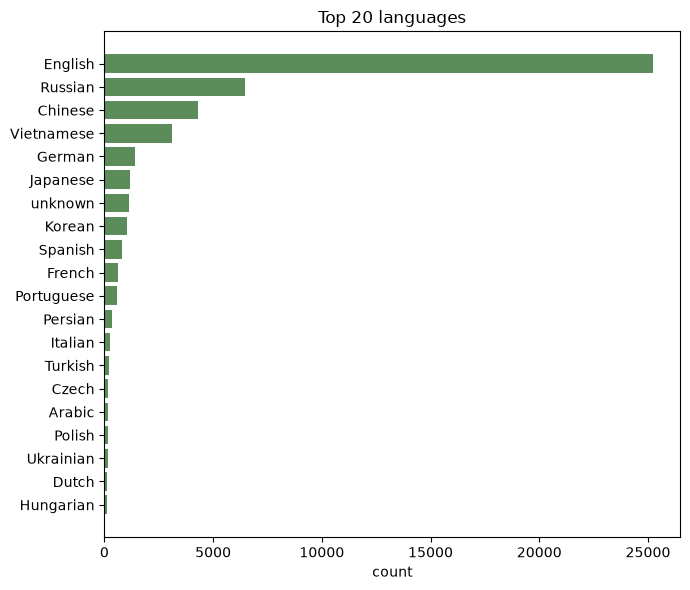

English: 52.0% | top-5 languages: 83.6% | languages with < 100 rows: 108


In [9]:
print("Number of languages:", train["language"].nunique())
fig, ax = plt.subplots(figsize=(7, 6))
U.plot_top_languages(train, top=20, ax=ax)
plt.tight_layout(); plt.show()
share = train["language"].value_counts(normalize=True)
print(f"English: {share['English']:.1%} | top-5 languages: {share.iloc[:5].sum():.1%} | "
      f"languages with < 100 rows: {(train['language'].value_counts() < 100).sum()}")

**Interpretation.** The data is truly **multilingual** (128 languages) but very **imbalanced**: English is 52 % of the battles and the top-5 languages (English, Russian, Chinese, Vietnamese, German) cover 83.6 %, while **108 languages have fewer than 100 examples**.
Consequence for modelling: word-level, language-specific tools (English tokenizers, stop-word lists) would not cover the long tail → we prefer **language-agnostic features** (lengths, markdown structure) and **character n-grams**, which work for every script.

In [10]:
lang_wr = (train.assign(a_wins=train["winner"].eq("model_a"))
                .groupby("language")["a_wins"].agg(["mean", "size"])
                .query("size >= 500").sort_values("size", ascending=False)
                .rename(columns={"mean": "P(A wins)", "size": "n"}))
lang_wr.round(3)

,P(A wins),n
language,,
English,0.490,25211
Russian,0.486,6455
Chinese,0.500,4310
Vietnamese,0.505,3103
German,0.520,1402
Japanese,0.496,1159
unknown,0.489,1128
Korean,0.510,1041
Spanish,0.508,790


**Interpretation.** For all large languages P(A wins) stays between ~0.47 and ~0.53, i.e. **the language itself does not decide who wins** — the differences are within what is expected from sampling noise for these group sizes. This supports building one model for all languages instead of per-language models.

### 3.3 Text length distributions and outliers

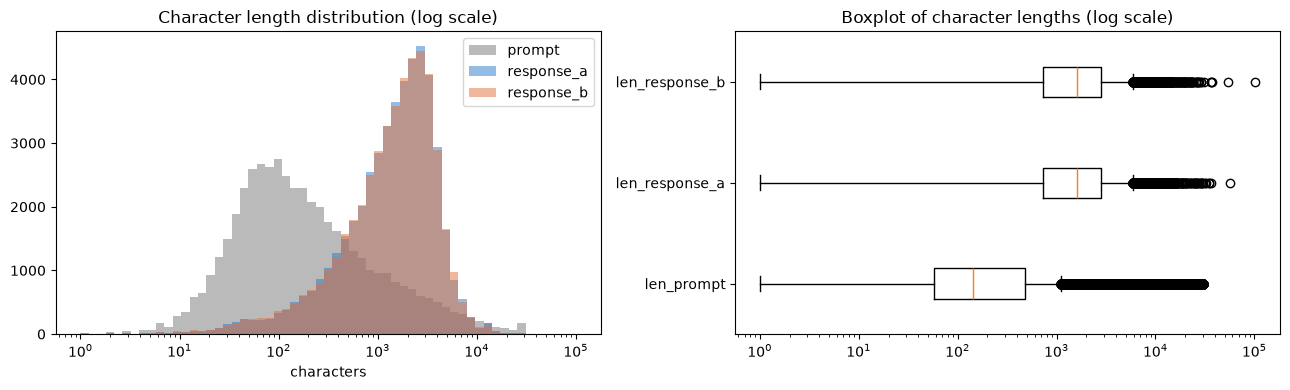

len_prompt      IQR outliers (>   1106 chars): 14.76%   > 2000 chars:  9.46%
len_response_a  IQR outliers (>   5902 chars):  3.21%   > 2000 chars: 40.75%
len_response_b  IQR outliers (>   5936 chars):  3.18%   > 2000 chars: 40.76%


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
U.plot_length_distributions(train, ax=axes[0])
axes[1].boxplot([lengths[c].clip(lower=1) for c in lengths], vert=False)
axes[1].set_yticks([1, 2, 3], list(lengths))
axes[1].set_xscale("log"); axes[1].set_title("Boxplot of character lengths (log scale)")
plt.tight_layout(); plt.show()

for c in lengths:
    q1, q3 = lengths[c].quantile([.25, .75])
    upper = q3 + 1.5 * (q3 - q1)
    print(f"{c:15s} IQR outliers (> {upper:6.0f} chars): {(lengths[c] > upper).mean():6.2%}   "
          f"> 2000 chars: {(lengths[c] > 2000).mean():6.2%}")

**Interpretation.** On the log scale the three distributions are roughly bell-shaped: prompts are short (median 142 chars) and answers are an order of magnitude longer (median ~1,600 chars). Responses A and B have practically the same distribution (expected, positions are random).
The boxplots show many **outliers on the long side**: 14.8 % of prompts and ~3.2 % of the answers are above the 1.5·IQR whisker. These are **real values** (long code, documents pasted into the prompt), not errors, so we do not remove them. Instead
* tree models / ratio features are robust to them,
* for TF-IDF we truncate each answer to 2,000 characters (~41 % of the answers are longer), which keeps the beginning of the answer — usually the most informative part — and bounds memory/time.

### 3.4 Relationship between length and the target (verbosity bias)

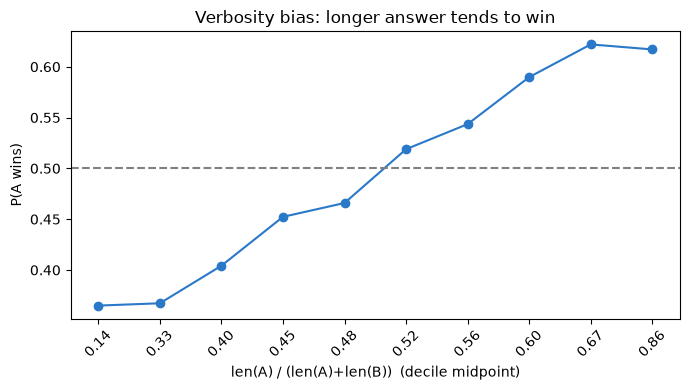

The longer response wins in 58.37% of the battles


In [12]:
fig, ax = plt.subplots(figsize=(7, 4))
U.plot_verbosity_bias(train, n_bins=10, ax=ax)
plt.tight_layout(); plt.show()
la, lb = lengths["len_response_a"], lengths["len_response_b"]
longer_wins = ((la > lb) & train["winner"].eq("model_a")) | ((lb > la) & train["winner"].eq("model_b"))
print(f"The longer response wins in {longer_wins[la != lb].mean():.2%} of the battles")

**Interpretation.** This is the strongest pattern in the data. When A is much shorter than B (left deciles) A wins only ~36 % of the time; when A is much longer (right deciles) it wins ~62 %. The curve rises monotonically and flattens at the extremes.
Overall **the longer answer wins 58.4 %** of the battles — a clear **verbosity bias** of the voters (as described in the competition). Length is therefore an obvious baseline rule (section 5) and length *differences / ratios* between A and B are key features.

### 3.5 Formatting (markdown) and the target

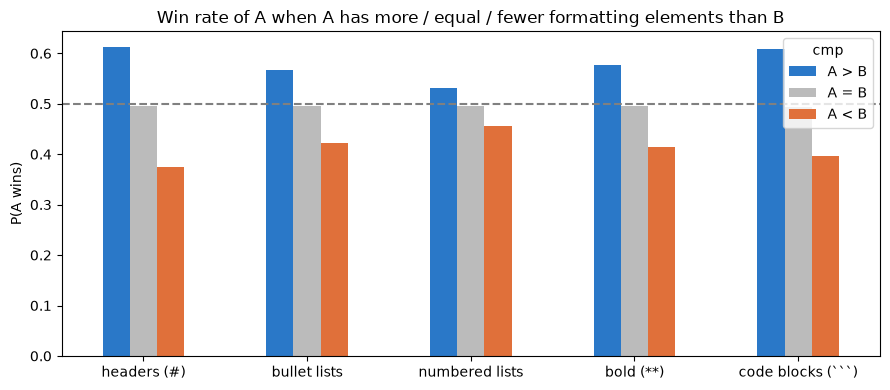

cmp,A > B,A = B,A < B
headers (#),0.613,0.496,0.374
bullet lists,0.566,0.495,0.421
numbered lists,0.531,0.496,0.456
bold (**),0.576,0.496,0.415
code blocks (```),0.609,0.494,0.397


In [13]:
patterns = {"headers (#)": r"(?m)^\s{0,3}#{1,6}\s", "bullet lists": r"(?m)^\s*[-*+•]\s+",
            "numbered lists": r"(?m)^\s*\d+[.)]\s+", "bold (**)": r"\*\*[^*]+\*\*", "code blocks (```)": r"```"}
fmt = {}
for name, pat in patterns.items():
    fmt[name] = U.feature_win_rate(train, train["response_a"].str.count(pat), train["response_b"].str.count(pat))["P(A wins)"]
fmt = pd.DataFrame(fmt).T[["A > B", "A = B", "A < B"]]
ax = fmt.plot.bar(figsize=(9, 4), color=["#2a78c8", "#bbbbbb", "#e0703a"], rot=0)
ax.axhline(0.5, ls="--", color="gray"); ax.set_ylabel("P(A wins)")
ax.set_title("Win rate of A when A has more / equal / fewer formatting elements than B")
plt.tight_layout(); plt.show()
fmt.round(3)

**Interpretation.** For every formatting element, the answer that contains **more** of it wins more often: with more headers A wins 61.3 % vs 37.4 % with fewer; similar gaps for code blocks (60.9 % vs 39.7 %) and bold text (57.6 % vs 41.5 %). Numbered lists have the weakest effect.
When both answers have the same amount (`A = B`, mostly "none") the win rate is ~0.50, i.e. the effect is driven by the *difference* between A and B. Voters prefer **structured, well-formatted** answers — partly because better models format more — so markdown counts and their A−B differences are included as features.

### 3.6 Refusals and special cases

In [14]:
refusal_re = r"I'm sorry|I am sorry|I can't|I cannot|as an AI|lo siento|не могу|抱歉|无法"
ref_a = train["response_a"].str.slice(0, 300).str.contains(refusal_re, case=False, regex=True)
ref_b = train["response_b"].str.slice(0, 300).str.contains(refusal_re, case=False, regex=True)
only_a, only_b = ref_a & ~ref_b, ref_b & ~ref_a
print(f"A looks like a refusal: {ref_a.mean():.2%} of rows")
print(f"P(A wins | only A refuses) = {train.loc[only_a, 'winner'].eq('model_a').mean():.3f}  (n={only_a.sum()})")
print(f"P(A wins | only B refuses) = {train.loc[only_b, 'winner'].eq('model_a').mean():.3f}  (n={only_b.sum()})")

A looks like a refusal: 2.22% of rows
P(A wins | only A refuses) = 0.227  (n=910)
P(A wins | only B refuses) = 0.738  (n=894)


**Interpretation.** About 2 % of the answers start like a refusal. When **only A refuses, A wins only 22.7 %** of the time; when only B refuses, A wins 73.8 %. Refusing is heavily penalised by users, so a (multilingual) refusal flag is a useful feature even if it is rare.

### 3.7 Which LLMs win?

Distinct models: 60


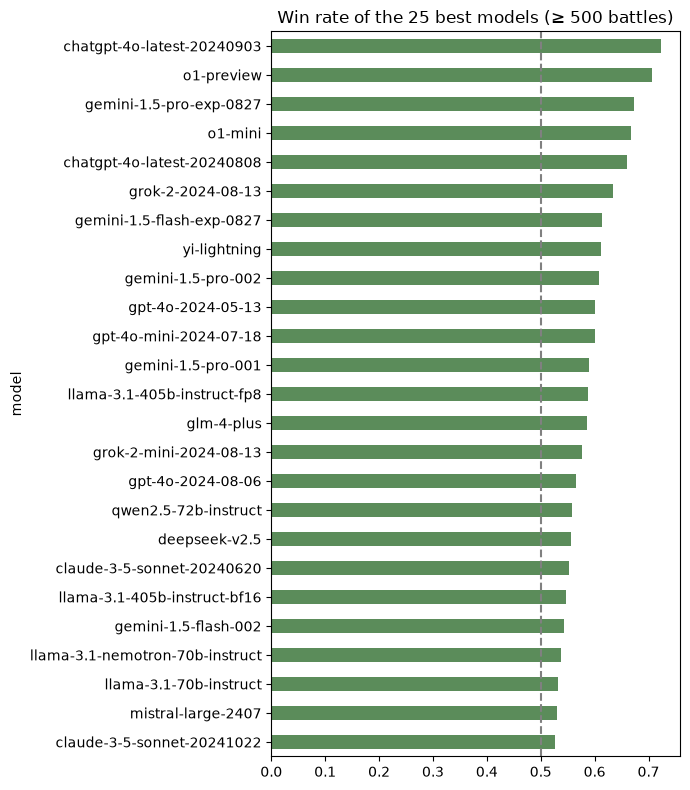

,win_rate,battles
model,,
chatgpt-4o-latest-20240903,0.722,3702
o1-preview,0.707,2366
gemini-1.5-pro-exp-0827,0.674,1003
o1-mini,0.667,2403
chatgpt-4o-latest-20240808,0.660,1375


In [15]:
print("Distinct models:", pd.concat([train["model_a"], train["model_b"]]).nunique())
wr = U.model_win_rates(train, min_battles=500)
fig, ax = plt.subplots(figsize=(7, 8))
wr["win_rate"].head(25)[::-1].plot.barh(ax=ax, color="#5b8c5a")
ax.axvline(0.5, ls="--", color="gray"); ax.set_title("Win rate of the 25 best models (≥ 500 battles)")
plt.tight_layout(); plt.show()
wr.head(5).round(3)

**Interpretation.** Win rates differ a lot between LLMs: the best models (chatgpt-4o-latest, o1-preview, gemini-1.5-pro-exp) win 67–72 % of their battles.
The model identity would therefore be a strong predictor, **but it is not available in the test set** (section 2.1). Our features must capture the *properties of the answer* that make strong models win (length, structure, no refusals, content).

### 3.8 Correlation of engineered features with the target
We compute the handcrafted features of section 4 here already and look at their linear correlation with the target (1 = B wins).

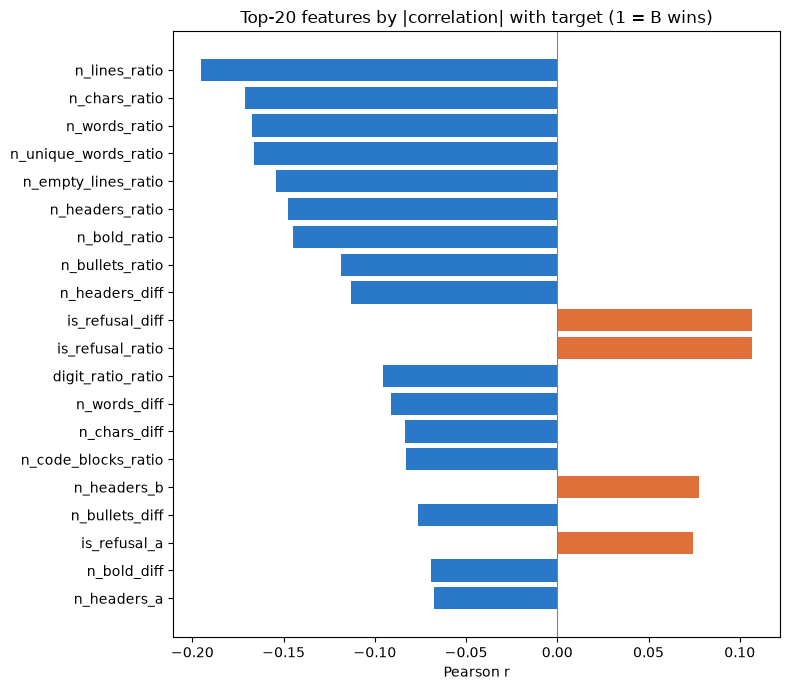

n_lines_ratio          -0.195
n_chars_ratio          -0.171
n_words_ratio          -0.167
n_unique_words_ratio   -0.166
n_empty_lines_ratio    -0.154
n_headers_ratio        -0.148
n_bold_ratio           -0.145
n_bullets_ratio        -0.119
dtype: float64

In [16]:
fe = HandcraftedFeatureExtractor()
X_hc = fe.transform(train).set_index(pd.Index(train["id"].astype(str)))
y = encode_target(train["winner"])
fig, ax = plt.subplots(figsize=(8, 7))
corr = U.plot_target_correlations(X_hc, y, top=20, ax=ax)
plt.tight_layout(); plt.show()
corr.head(8).round(3)

**Interpretation.** The features most correlated with the target are the **A / (A+B) ratios of size and structure** (lines, characters, words, unique words, empty lines, headers, bold, bullets). The correlation is **negative** because the target is 1 when B wins: a larger share for A means A tends to win.
The correlations are only moderate (|r| ≤ 0.2), so no single feature solves the task, but they confirm the EDA findings (verbosity + formatting bias). Ratios work better than raw differences because they are scale-free (a 500-character difference matters more for short answers than for long ones).

## 4. Preprocessing
### 4.1 Cleaning
* Text columns are cast to `str` and missing values would be replaced by `""` (`load_competition_data`). There are none, but the hidden test set could contain some.
* We **do not** lower-case or remove punctuation / markdown: formatting is itself a strong signal (section 3.5).
* Duplicated prompts are **kept**: the same prompt answered by different model pairs is a different sample with its own label.
* Identical A/B answers are kept (only a handful, removing them would not change anything).
* Very long texts are **truncated to 2,000 characters** for the TF-IDF model only (memory/speed); their length is still fully captured by the handcrafted length features.

In [17]:
print("Missing values after loading:", int(train.isna().sum().sum()))
print(f"Responses longer than 2,000 chars (truncated for TF-IDF): "
      f"{((lengths['len_response_a'] > 2000) | (lengths['len_response_b'] > 2000)).mean():.1%} of rows")

Missing values after loading: 0
Responses longer than 2,000 chars (truncated for TF-IDF): 51.5% of rows


### 4.2 Imputation
No imputation is necessary: there are no missing values (section 2.3). Ratio features use a safe default (`0.5` when both counts are 0) instead of producing NaN.

### 4.3 Encoding
* **Target:** `model_a → 0`, `model_b → 1` (`encode_target`).
* **`language`, `model_a`, `model_b`:** *not used* as features. They do not exist in the test set (section 2.1); using model names would also make the model learn "which LLM is strong" instead of "which answer is better".
* **Text → numbers**, two complementary representations:
  1. **Handcrafted, language-agnostic features** (`HandcraftedFeatureExtractor`): 21 statistics per response (length, words, lines, headers, lists, bold, code blocks, tables, URLs, LaTeX, emojis, digits, refusals, …), each as `A`, `B`, `A − B` and `A / (A + B)`, plus prompt length and prompt–response overlap → **95 features**.
  2. **Character n-grams (2–4)** with the hashing trick (`hashed_char_counts`, 2²⁰ dimensions). Character n-grams work for every script (Latin, Cyrillic, CJK …), so no language-specific tokenizer is needed. They are re-weighted with **TF-IDF** and the model sees `tfidf(A) − tfidf(B)`.

In [18]:
print("Handcrafted feature matrix:", X_hc.shape)
X_hc[["n_chars_a", "n_chars_b", "n_chars_diff", "n_chars_ratio", "n_headers_diff", "is_refusal_a", "prompt_overlap_word_diff"]].describe().T.round(3)

Handcrafted feature matrix: (48439, 95)


,count,mean,std,min,25%,50%,75%,max
n_chars_a,48439.0,2015.563,1917.224,1.000,725.000,1599.0,2796.000,57222.0
n_chars_b,48439.0,2020.373,1957.197,1.000,724.000,1605.0,2809.000,101944.0
n_chars_diff,48439.0,-4.810,1952.753,-101658.000,-548.000,1.0,553.000,49091.0
n_chars_ratio,48439.0,0.500,0.174,0.001,0.401,0.5,0.600,1.0
n_headers_diff,48439.0,0.003,4.288,-55.000,0.000,0.0,0.000,371.0
is_refusal_a,48439.0,0.026,0.159,0.000,0.000,0.0,0.000,1.0
prompt_overlap_word_diff,48439.0,-0.000,0.102,-1.000,-0.025,0.0,0.023,1.0


### 4.4 Scaling
The features live on very different scales (e.g. `n_chars_diff` ranges over tens of thousands, ratios lie in [0, 1], flags are 0/1).
* **Logistic regression** is sensitive to scale → `StandardScaler` inside an sklearn `Pipeline`, so the scaler is fitted on the training part only (no leakage).
* **LightGBM** (trees) is scale-invariant → no scaling.
* **TF-IDF** vectors are L2-normalised per response; `sublinear_tf` dampens very frequent n-grams.

### 4.5 Position-bias augmentation
The TF-IDF model is trained on `(A − B, y)` **and** the swapped copy `(B − A, 1 − y)`. This makes the model symmetric: swapping the answers flips the prediction.

### 4.6 Train / validation split
80 % / 20 %, stratified on the target, `random_state=42`. The validation part is used for the main baseline score; 5-fold CV is added as a robustness check.

In [19]:
tr_df, va_df = train_valid_split(train, test_size=0.2, random_state=SEED)
y_tr, y_va = encode_target(tr_df["winner"]), encode_target(va_df["winner"])
print("train:", tr_df.shape, " validation:", va_df.shape,
      f"| P(model_b) train={y_tr.mean():.4f} valid={y_va.mean():.4f}")

# char n-gram counts are computed once (stateless) and looked up by id inside every model
counts = (hashed_char_counts(train["response_a"]), hashed_char_counts(train["response_b"]), train["id"].values)
print("char n-gram matrix:", counts[0].shape, f"(~{counts[0].nnz / len(train):.0f} non-zero n-grams per response)")

train: (38751, 8)  validation: (9688, 8) | P(model_b) train=0.5054 valid=0.5054


char n-gram matrix: (48439, 1048576) (~1354 non-zero n-grams per response)


## 5. Baseline model
| # | Model | Idea |
|---|-------|------|
| 0 | Majority class | lower bound |
| 1 | Longer response wins | rule from section 3.4, no training |
| 2 | **Logistic regression** on handcrafted features | the simple baseline |
| 3 | LightGBM on handcrafted features | non-linear interactions |
| 4 | Char TF-IDF difference + logistic regression | content of the answers |
| 5 | Blend of 3 and 4 | average of the probabilities |

### 5.1 Validation score (80/20 split, accuracy)

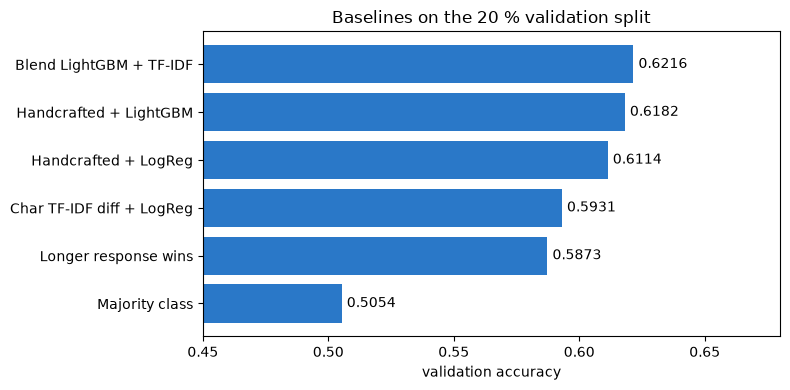

,validation accuracy
Blend LightGBM + TF-IDF,0.6216
Handcrafted + LightGBM,0.6182
Handcrafted + LogReg,0.6114
Char TF-IDF diff + LogReg,0.5931
Longer response wins,0.5873
Majority class,0.5054


In [20]:
factories = {
    "Majority class": lambda: MajorityClassBaseline(),
    "Longer response wins": lambda: LengthHeuristicBaseline(),
    "Handcrafted + LogReg": lambda: FeatureModelBaseline("logreg", precomputed=X_hc),
    "Handcrafted + LightGBM": lambda: FeatureModelBaseline("lgbm", precomputed=X_hc),
    "Char TF-IDF diff + LogReg": lambda: TfidfDiffBaseline(precomputed=counts),
}
hold = {name: holdout_evaluate(f(), tr_df, y_tr, va_df, y_va) for name, f in factories.items()}
p_blend = 0.5 * hold["Handcrafted + LightGBM"]["proba"] + 0.5 * hold["Char TF-IDF diff + LogReg"]["proba"]

from sklearn.metrics import accuracy_score
val = pd.Series({k: v["valid_accuracy"] for k, v in hold.items()})
val["Blend LightGBM + TF-IDF"] = accuracy_score(y_va, p_blend >= 0.5)
val = val.sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(val.index, val.values, color="#2a78c8")
for i, v in enumerate(val.values):
    ax.text(v + 0.002, i, f"{v:.4f}", va="center")
ax.set_xlim(0.45, 0.68); ax.set_xlabel("validation accuracy"); ax.set_title("Baselines on the 20 % validation split")
plt.tight_layout(); plt.show()
val.sort_values(ascending=False).round(4).to_frame("validation accuracy")

**Interpretation (validation accuracy, 9,688 battles).**
* Majority class: **0.505** (lower bound). The single rule "longer answer wins": **0.587** (+8 points without any training).
* The simple baseline, **logistic regression on handcrafted features: 0.611**. LightGBM on the same features: **0.618** — the non-linear model adds a little by combining features.
* Char TF-IDF difference alone: 0.593 — content n-grams are weaker alone than structure, but they carry **different information**: the blend of LightGBM and TF-IDF is the best model with **0.622**.

### 5.2 Robustness check: 5-fold stratified cross-validation

In [21]:
cv = [cross_validate(f, train, y, n_splits=5, random_state=SEED, verbose=False) for f in factories.values()]
oof = {r["model"]: r["oof"] for r in cv}
cv_table = summarize_results(cv)
oof_blend = 0.5 * oof["Handcrafted + LightGBM"] + 0.5 * oof["Char TF-IDF diff + LogReg"]
cv_table.loc[len(cv_table)] = ["Blend LightGBM + TF-IDF", accuracy_score(y, oof_blend >= 0.5), np.nan, np.nan, np.nan, np.nan]
cv_table.sort_values("cv_accuracy", ascending=False).round(4).reset_index(drop=True)

,model,cv_accuracy,cv_std,auc,logloss,time_s
0,Blend LightGBM + TF-IDF,0.6271,NaN,NaN,NaN,NaN
1,Handcrafted + LightGBM,0.6128,0.0028,0.6647,0.6459,19.1088
2,Char TF-IDF diff + LogReg,0.6046,0.0044,0.6501,0.6590,132.6645
3,Handcrafted + LogReg,0.6039,0.0025,0.6475,0.6580,9.0137
4,Longer response wins,0.5837,0.0022,0.5837,5.7459,0.8562
5,Majority class,0.5054,0.0000,0.5000,0.6931,0.7433


**Interpretation.** 5-fold CV gives the same picture with small standard deviations (≤ 0.004), so the differences between models are stable. The blend reaches **0.627** out-of-fold, close to the 0.622 of the single validation split.
(The TF-IDF model is somewhat better in CV than on the single split — one split of ~9.7k rows has about ±0.5 points of noise.) AUC values of ~0.65 show that the task is hard: human preference is noisy.

### 5.3 Error analysis
**Confusion matrix of the blend on the validation split**

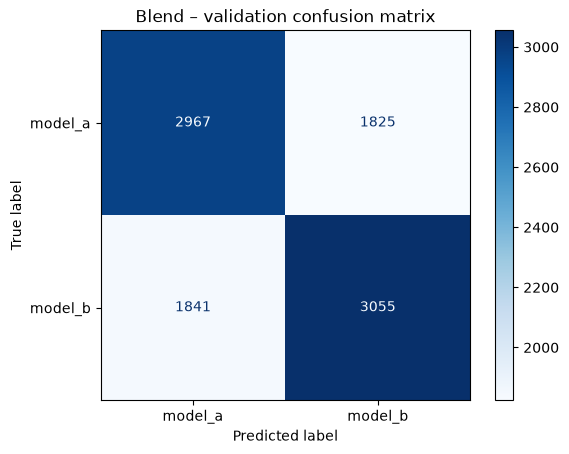

recall model_a = 0.619 | recall model_b = 0.624 | predicted model_b share = 0.504


In [22]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(y_va, (p_blend >= 0.5).astype(int))
ConfusionMatrixDisplay(cm, display_labels=["model_a", "model_b"]).plot(cmap="Blues", values_format="d")
plt.title("Blend – validation confusion matrix"); plt.show()
recall = cm.diagonal() / cm.sum(axis=1)
print(f"recall model_a = {recall[0]:.3f} | recall model_b = {recall[1]:.3f} | "
      f"predicted model_b share = {(p_blend >= 0.5).mean():.3f}")

**Interpretation.** Errors are **balanced between the two classes** (similar recall for `model_a` and `model_b`, and the share of predicted `model_b` is close to the true 50.5 %): thanks to the symmetric features and the swap augmentation the model has no position bias of its own. The ~38 % errors are spread over both classes, i.e. the model is not simply guessing one side.

**Most important features (LightGBM, gain)**

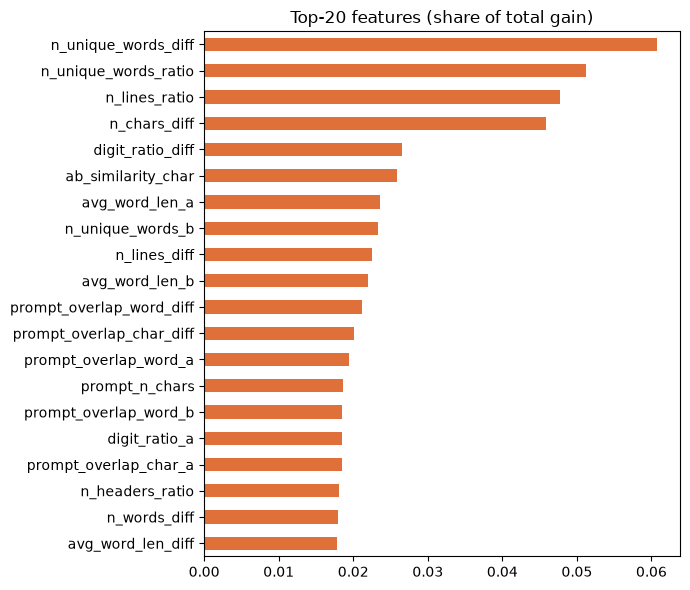

,share of gain
n_unique_words_diff,0.061
n_unique_words_ratio,0.051
n_lines_ratio,0.048
n_chars_diff,0.046
digit_ratio_diff,0.027
ab_similarity_char,0.026
avg_word_len_a,0.024
n_unique_words_b,0.023
n_lines_diff,0.023
avg_word_len_b,0.022


In [23]:
imp = hold["Handcrafted + LightGBM"]["fitted"].feature_importance()
fig, ax = plt.subplots(figsize=(7, 6))
(imp.head(20) / imp.sum())[::-1].plot.barh(ax=ax, color="#e0703a")
ax.set_title("Top-20 features (share of total gain)")
plt.tight_layout(); plt.show()
(imp.head(10) / imp.sum()).round(3).to_frame("share of gain")

**Interpretation.** LightGBM relies most on **relative size features**: the difference / ratio of unique words, lines and characters between A and B (together ~23 % of the total gain) — the verbosity bias found in 3.4 and the correlations in 3.8.
Next come features describing the *style* of the answers (`digit_ratio_diff`, average word length) and how similar A and B are (`ab_similarity_char`): when the answers are very similar the length signal is less reliable, and the trees use this interaction.
Rare flags (refusal, code, URLs) have a small total gain because they occur in few rows, but they help in exactly those cases.

**Accuracy per language and per length gap (5-fold out-of-fold blend)**

In [24]:
accuracy_by_group(y, oof_blend, train["language"], min_count=500).round(3)

,n,accuracy
g,,
English,25211.0,0.617
Russian,6455.0,0.630
Chinese,4310.0,0.663
Vietnamese,3103.0,0.636
German,1402.0,0.611
Japanese,1159.0,0.643
unknown,1128.0,0.654
Korean,1041.0,0.649
Spanish,790.0,0.637


In [25]:
ratio = (la / (la + lb).replace(0, np.nan)).fillna(0.5)
gap = pd.cut((ratio - 0.5).abs(), [0, .05, .1, .2, .3, .5], include_lowest=True)
(pd.DataFrame({"length gap |ratio − 0.5|": gap, "correct": (oof_blend >= 0.5) == y})
   .groupby("length gap |ratio − 0.5|", observed=True)["correct"].agg(["mean", "size"])
   .rename(columns={"mean": "accuracy", "size": "n"}).round(3))

,accuracy,n
length gap |ratio − 0.5|,,
"(-0.001, 0.05]",0.574,13556
"(0.05, 0.1]",0.606,10800
"(0.1, 0.2]",0.643,13247
"(0.2, 0.3]",0.670,5870
"(0.3, 0.5]",0.726,4966


**Interpretation.**
* **Per language:** accuracy is similar across languages (0.61–0.66); English is not the best one, so the language-agnostic features transfer well to other languages.
* **Per length gap:** when the two answers have almost the same length (|ratio − 0.5| ≤ 0.05, 28 % of the data) the model is only 57 % accurate; when one answer is much longer it reaches **73 %**.
  The baseline mostly relies on length/structure; it struggles when the answers look alike and the decision depends on **correctness and content** → this is where Assignment 2 should improve.

## 6. Kaggle submission
The final baseline (blend of LightGBM + char TF-IDF) is trained on the **full** training set. The code below produces `submission.csv` for the public test sample;
on Kaggle the same models are run by `kaggle/kaggle_submission.ipynb` (internet off), where the hidden test set is swapped in.

In [26]:
lgbm_full = FeatureModelBaseline("lgbm", precomputed=X_hc).fit(train, y)
tfidf_full = TfidfDiffBaseline(precomputed=counts).fit(train, y)
# test ids are not in the precomputed tables -> features are computed on the fly for test
p_test = 0.5 * lgbm_full.predict_proba(test) + 0.5 * tfidf_full.predict_proba(test)
sub = U.make_submission(test["id"], p_test, "submission.csv")
sub

,id,winner
0,327228,model_b
1,1139415,model_b
2,1235630,model_b


**Kaggle late submission** (`kaggle/kaggle_submission.ipynb`, same blend, trained on the full training set):

| Model | Validation acc. | 5-fold CV acc. | Kaggle **private** score | ≈ rank on final private LB |
|---|---|---|---|---|
| Blend LightGBM + char TF-IDF | 0.6216 | 0.6271 | **0.6224** | ~586 |

The Kaggle score (0.622) is in line with our local validation (0.622–0.627), so the validation setup is reliable and the model does not overfit. (Late submissions are not ranked; the rank is where the score would be placed on the final private leaderboard.)

![Kaggle late submission](submissions/kaggle_late_submission.png)

## 7. Conclusion

**Key findings**
* Balanced binary task (50.5 % / 49.5 %), 48k battles, 128 languages (English 52 %), no missing values and practically no duplicates.
* Human votes have strong, measurable biases: **longer** answers win 58.4 %, answers with **more structure** (headers, code blocks, bold) win more, **refusals** lose ~77 % of the time. Position bias is negligible.
* Model identities are very predictive but not available at test time.

**Baseline results:** logistic regression on 95 language-agnostic features: **0.611** validation accuracy; the best baseline (LightGBM + char TF-IDF blend) reaches **0.622** validation / **0.627** CV and **0.6224** on the Kaggle private leaderboard (late submission).

**Next steps (Assignment 2)**
* The baseline fails when both answers look similar (57 % accuracy) because it does not understand the *content*. We will fine-tune a **multilingual transformer** (e.g. mDeBERTa-v3 or a small multilingual LLM with LoRA) on `[prompt, response_a, response_b]` with smart truncation of long texts.
* Use **A/B swap augmentation** (train) and test-time swapping to remove position bias.
* **Stack** the transformer prediction with the handcrafted features in LightGBM.